# APS360 Progress Experiments — QFrCoLA

**Topic:** Quebec French linguistic acceptability classification, with emphasis on anglicisms.

**Research question:** Does a word-embedding BiLSTM outperform a TF–IDF logistic regression baseline under a **source-disjoint** split, and do character-level features or training modifications help?

This notebook contains the **executed experiments and saved outputs** supporting the APS360 progress report. To reproduce the pipeline, run cells from top to bottom in Google Colab (GPU recommended). Results may vary slightly with the hardware or library versions; do not interpret output shown in the saved notebook as evidence that a fresh run was performed.

- **Input:** Quebec French sentence
- **Output:** binary label (`0 = unacceptable`, `1 = acceptable`)
- **Dataset:** [`graalul/qfrcola`](https://huggingface.co/datasets/graalul/qfrcola), CC BY-NC-SA 4.0
- **Splitting:** group by source page, with connected groups for repeated sentences; prevent source overlap across train, validation, and test
- **Target split ratio:** approximately 70% / 15% / 15% (the selected split uses seed 372)
- **Evaluations:** TF–IDF baseline, word-level BiLSTM, character CNN + BiLSTM, and class-weight/capacity ablations
- **Test protocol:** held-out test metrics were computed for the initial TF–IDF and word-level BiLSTM experiments. Later model changes are compared using validation only.

**Course report:** the supplied NeurIPS-style LaTeX template was used for the three-page progress report, with references on an additional page.

**Dataset reference:** Beauchemin & Khoury, *QFrCoLA: a Quebec-French Corpus of Linguistic Acceptability Judgments*, EMNLP 2025 ([paper](https://aclanthology.org/2025.emnlp-main.6/)).


## Part A — Download and inspect QFrCoLA

In [1]:
%pip -q install -U datasets scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, random, unicodedata, copy, json, sys, platform
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 360
random.seed(SEED)
np.random.seed(SEED)
OUT = Path('qfrcola_results')
OUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Output directory:', OUT.resolve())

C:\Users\ethan\miniconda3\envs\aps360\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.18 | pandas: 3.1.1
Output directory: C:\Users\ethan\qfrcola_results


In [3]:
dataset = load_dataset('graalul/qfrcola')
print('Official splits:', {k: len(v) for k, v in dataset.items()})
df_raw = pd.concat(
    [dataset[k].to_pandas().assign(original_split=k) for k in dataset],
    ignore_index=True
)
required = {'sentence','label','source','category'}
assert required.issubset(df_raw.columns), f'Missing columns: {required - set(df_raw.columns)}'
print('Raw rows:', len(df_raw))
print('Columns:', df_raw.columns.tolist())
display(df_raw[['sentence','label','category','source']].head(5))
print('Missing values:')
print(df_raw[['sentence','label','category','source']].isna().sum().to_string())
print('Raw label counts:', df_raw['label'].value_counts(dropna=False).to_dict())
print('Raw categories:')
display(df_raw['category'].value_counts(dropna=False).to_frame('count'))

Official splits: {'train': 15846, 'validation': 1761, 'test': 7546}
Raw rows: 25153
Columns: ['label', 'sentence', 'source', 'category', 'original_split']


,sentence,label,category,source
0,Je participerai au congrès à moins que des obl...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
1,Les météorologues ne s’expliquent pas la vague...,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...
2,"La journée était calme : point de vent, poing ...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3,Le juge s’est objecté à la remise en liberté d...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
4,L’adjectif s’accorde avec le nom ou le pronom ...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...


Missing values:
sentence    0
label       0
category    0
source      0
Raw label counts: {1: 17479, 0: 7674}
Raw categories:


,count
category,
morphology,10642
semantic,5442
syntax,5152
anglicism,3917


## Part B — Clean, deduplicate and connect shared sources

Keep the **accents, case and apostrophe spellings** intact in the stored sentences (e.g. `l’`, `qu’`). We normalize Unicode (NFC) and repeated whitespace only; dropping accents or punctuation could change acceptability labels.

For repeated texts, first link all their source URLs into one connected group; then remove duplicate text examples. If an identical normalized sentence has both labels, exclude all occurrences and report the count rather than arbitrarily assigning a label.

In [4]:
def normalize_sentence(s):
    s = unicodedata.normalize('NFC', str(s))
    return re.sub(r'\s+', ' ', s).strip()

df = df_raw.copy()
# Drop malformed rows before string conversion (NaN must not become the literal 'nan').
missing = df[['sentence','source','label']].isna().any(axis=1)
df = df.loc[~missing].copy()
df['sentence'] = df['sentence'].map(normalize_sentence)
df['source'] = df['source'].astype(str).str.strip()
df['category'] = df['category'].fillna('unknown').astype(str).str.strip().str.lower()
df['label'] = pd.to_numeric(df['label'], errors='coerce')
df = df.loc[(df['sentence'] != '') & (df['source'] != '') & df['label'].isin([0,1])].copy()
df['label'] = df['label'].astype(int)

class DSU:
    def __init__(self, items):
        self.parent = {x:x for x in items}
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra

dsu = DSU(df['source'].unique())
# A sentence appearing on two different source pages links those pages.
for _, urls in df.groupby('sentence', sort=False)['source']:
    unique_urls = urls.unique()
    for url in unique_urls[1:]:
        dsu.union(unique_urls[0], url)

conflicting_sentences = df.groupby('sentence')['label'].nunique()
conflicting_sentences = set(conflicting_sentences[conflicting_sentences > 1].index)
conflicting_rows = int(df['sentence'].isin(conflicting_sentences).sum())
n_before = len(df)
df = df.loc[~df['sentence'].isin(conflicting_sentences)].drop_duplicates('sentence', keep='first').copy()
df['source_group'] = df['source'].map(dsu.find)

audit = {
    'raw_rows': len(df_raw), 'malformed_or_missing_removed': len(df_raw) - n_before,
    'conflicting_sentences': len(conflicting_sentences),
    'conflicting_rows_removed': conflicting_rows,
    'exact_duplicate_rows_removed': int(n_before - conflicting_rows - len(df)),
    'cleaned_rows': len(df), 'source_urls_remaining': df['source'].nunique(),
    'connected_source_groups': df['source_group'].nunique()
}
print('Cleaning audit:')
print(json.dumps(audit, indent=2, ensure_ascii=False))
assert df['sentence'].is_unique
assert not df[['sentence','source']].isna().any().any()
assert set(df['label'].unique()) <= {0,1}
assert df['source_group'].nunique() >= 3, 'Too few disjoint source groups to split into 3 partitions'
if conflicting_sentences:
    print('Review conflicting texts:')
    display(pd.DataFrame({'sentence': sorted(conflicting_sentences)}).head(8))
display(df[['sentence','label','category','source','source_group']].head(4))

Cleaning audit:
{
  "raw_rows": 25153,
  "malformed_or_missing_removed": 0,
  "conflicting_sentences": 0,
  "conflicting_rows_removed": 0,
  "exact_duplicate_rows_removed": 0,
  "cleaned_rows": 25153,
  "source_urls_remaining": 2798,
  "connected_source_groups": 2798
}


,sentence,label,category,source,source_group
0,Je participerai au congrès à moins que des obl...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
1,Les météorologues ne s’expliquent pas la vague...,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...
2,"La journée était calme : point de vent, poing ...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...
3,Le juge s’est objecté à la remise en liberté d...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...


## Part C — 70/15/15 split grouped by source page

The default QFrCoLA splits may not follow the proposed grouping scheme, so this experiment **pools all 25,153 in-domain examples before splitting**. The `source_group` key is the connected component of all URLs sharing a normalized sentence. We select a deterministic random split close to target sizes and class balance, **without using model predictions**.

In [5]:
def score_candidate(frame, inds):
    target = [0.70, 0.15, 0.15]
    n = len(frame)
    pos_share = frame['label'].mean()
    score = 0.0
    for ids, t in zip(inds, target):
        sub = frame.iloc[ids]
        if sub['label'].nunique() < 2 or len(sub) == 0:
            return float('inf')
        score += 3.0 * abs(len(sub) / n - t)
        score += abs(sub['label'].mean() - pos_share)
        # Keep anglicism representation in all partitions where feasible.
        if 'anglicism' in set(frame['category']) and not (sub['category'] == 'anglicism').any():
            score += 3
    return score

best = None
for trial in range(50):
    randseed = SEED + trial
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=randseed)
    trainval_i, test_i = next(splitter.split(df, groups=df['source_group']))
    trainval = df.iloc[trainval_i]
    splitter2 = GroupShuffleSplit(n_splits=1, test_size=(0.15 / 0.85), random_state=randseed + 10000)
    train_local, val_local = next(splitter2.split(trainval, groups=trainval['source_group']))
    train_i, val_i = trainval_i[train_local], trainval_i[val_local]
    ids = (train_i, val_i, test_i)
    score = score_candidate(df, ids)
    if best is None or score < best[0]:
        best = (score, randseed, ids)

assert np.isfinite(best[0]), 'Could not obtain a split with both labels and anglicisms in all groups'
_, chosen_seed, (train_i, val_i, test_i) = best
split_frames = [df.iloc[idx].copy() for idx in (train_i, val_i, test_i)]
for s, name in zip(split_frames, ['train','validation','test']):
    s['split'] = name
train_df, val_df, test_df = split_frames
full = pd.concat(split_frames, ignore_index=True)
assert sum(map(len, split_frames)) == len(df)
assert len(set(train_df.source_group) & set(val_df.source_group)) == 0
assert len(set(train_df.source_group) & set(test_df.source_group)) == 0
assert len(set(val_df.source_group) & set(test_df.source_group)) == 0
assert len(set(train_df.source) & set(test_df.source)) == 0
assert len(set(train_df.sentence) & set(test_df.sentence)) == 0
print(f'Selected deterministic split seed: {chosen_seed}; score: {best[0]:.4f}')
print('No shared source groups, URLs or normalized sentences across partitions.')
print('Split sizes:', {k:len(d) for k,d in zip(['train','validation','test'],split_frames)})

Selected deterministic split seed: 372; score: 0.0246
No shared source groups, URLs or normalized sentences across partitions.
Split sizes: {'train': 17580, 'validation': 3734, 'test': 3839}


Summary:


,rows,source_pages,source_groups,acceptable_rate,percent
split,,,,,
train,17580,1958,1958,0.695,69.892
validation,3734,420,420,0.690,14.845
test,3839,420,420,0.698,15.263


Class counts by split:


label,unacceptable (0),acceptable (1)
split,,
train,5358,12222
validation,1158,2576
test,1158,2681


Category counts by split:


split,train,validation,test,all
category,,,,
morphology,7308,1718,1616,10642
semantic,3811,695,936,5442
syntax,3630,777,745,5152
anglicism,2831,544,542,3917


Anglicism label counts:


label,0,1
split,,
train,1169,1662
validation,235,309
test,231,311


Example of cleaned training data:


,sentence,label,category,source
14961,La sculpture est le médium favori de Karen.,0,anglicism,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
2673,Ton frère prévoit changer son baladeur MP3 pou...,1,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...
2322,Les personnes qui font des exercices à haute i...,0,anglicism,https://vitrinelinguistique.oqlf.gouv.qc.ca/21...
5423,Cette robe griffée vaut 600 dollars.,1,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...
13964,La journaliste avait appris cette nouvelle de ...,1,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...


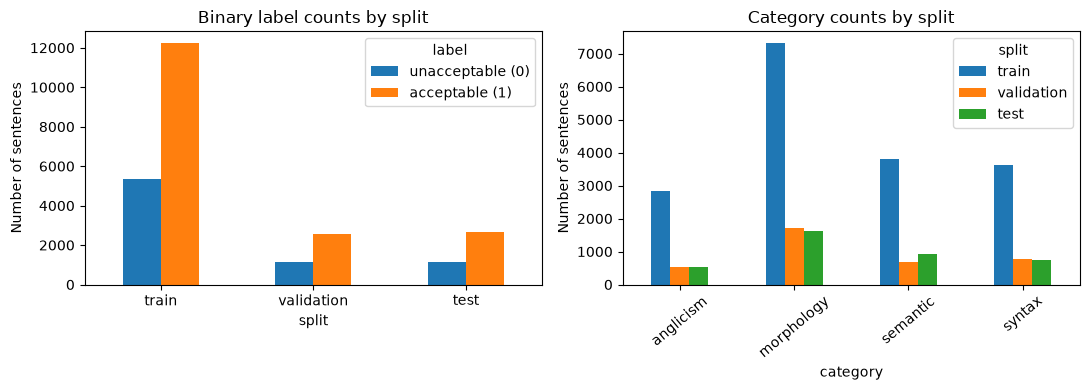

In [6]:
summary = full.groupby('split').agg(
    rows=('sentence','size'), source_pages=('source','nunique'),
    source_groups=('source_group','nunique'), acceptable_rate=('label','mean')
).reindex(['train','validation','test'])
summary['percent'] = 100 * summary['rows'] / len(full)
print('Summary:')
display(summary.round(3))

label_counts = pd.crosstab(full['split'], full['label']).reindex(['train','validation','test'], fill_value=0)
label_counts = label_counts.reindex(columns=[0,1],fill_value=0).rename(columns={0:'unacceptable (0)',1:'acceptable (1)'})
print('Class counts by split:')
display(label_counts)

category_counts = pd.crosstab(full['category'],full['split']).reindex(columns=['train','validation','test'], fill_value=0)
category_counts['all'] = category_counts.sum(axis=1)
print('Category counts by split:')
display(category_counts.sort_values('all',ascending=False))

anglicisms = full.loc[full['category'] == 'anglicism']
print('Anglicism label counts:')
display(pd.crosstab(anglicisms['split'], anglicisms['label']).reindex(['train','validation','test'], fill_value=0))
print('Example of cleaned training data:')
display(train_df[['sentence','label','category','source']].sample(min(5,len(train_df)),random_state=SEED))

summary.to_csv(OUT/'split_summary.csv')
label_counts.to_csv(OUT/'label_counts.csv')
category_counts.to_csv(OUT/'category_counts.csv')
for name, ds in zip(['train','validation','test'],split_frames):
    ds[['sentence','label','source','category','source_group']].to_csv(OUT/f'{name}.csv',index=False)
with open(OUT/'cleaning_audit.json','w',encoding='utf-8') as f:
    json.dump({**audit, 'split_seed':chosen_seed},f,indent=2,ensure_ascii=False)

fig, axs = plt.subplots(1,2,figsize=(11,4))
label_counts.plot(kind='bar', ax=axs[0], title='Binary label counts by split', rot=0)
category_counts.drop(columns='all').plot(kind='bar', ax=axs[1], title='Category counts by split', rot=40)
for ax in axs: ax.set_ylabel('Number of sentences')
fig.tight_layout()
fig.savefig(OUT/'split_distributions.png',dpi=180,bbox_inches='tight')
plt.show()

## Part D — French tokenizer sanity check

For the neural model, preserve elisions inside tokens such as `l’amour` and `qu’il`; preserve accented letters. We lowercase for vocabulary lookup but keep the original string for examples and output.

In [7]:
TOKEN_RE = re.compile(r"[^\W_]+(?:[’'-][^\W_]+)*|[^\w\s]",re.UNICODE)
def tokenize(text):
    return TOKEN_RE.findall(text.lower())
for example in [
    "J'aime l’école et qu’il soit prêt.",
    "L’assurance-emploi est importante au Québec.",
    "Je n’en ai pas besoin !",
]:
    print(example, '\n  ', tokenize(example))
assert 'l’école' in tokenize('Il aime l’école')
assert 'qu’il' in tokenize('Je veux qu’il parte')

J'aime l’école et qu’il soit prêt. 
   ["j'aime", 'l’école', 'et', 'qu’il', 'soit', 'prêt', '.']
L’assurance-emploi est importante au Québec. 
   ['l’assurance-emploi', 'est', 'importante', 'au', 'québec', '.']
Je n’en ai pas besoin ! 
   ['je', 'n’en', 'ai', 'pas', 'besoin', '!']


## Part E — Non-neural baseline: TF–IDF + Logistic Regression

Fit **TF–IDF using only the training partition**; select `C` and `class_weight` using **validation macro-F1**. Once fixed, evaluate on the test set one time. Keep class imbalance visible through per-class F1 and MCC.

In [8]:
def evaluate(y_true, pred):
    return {
        'accuracy': float(accuracy_score(y_true,pred)),
        'macro_f1': float(f1_score(y_true,pred,average='macro',zero_division=0)),
        'mcc': float(matthews_corrcoef(y_true,pred)),
        'f1_unacceptable': float(f1_score(y_true,pred,pos_label=0,zero_division=0)),
        'f1_acceptable': float(f1_score(y_true,pred,pos_label=1,zero_division=0))
    }

def tfidf_logreg(C, class_weight):
    return Pipeline([
        ('tfidf',TfidfVectorizer(
            lowercase=True, ngram_range=(1,2), min_df=2, max_features=100000,
            sublinear_tf=True, token_pattern=r"(?u)\b\w[\w’'-]*\b")),
        ('lr',LogisticRegression(C=C,class_weight=class_weight,max_iter=1500,random_state=SEED))
    ])

baseline_trials = []
for C in [0.1, 1.0, 10.0]:
    for weight in [None,'balanced']:
        model = tfidf_logreg(C,weight)
        model.fit(train_df['sentence'],train_df['label'])
        pred = model.predict(val_df['sentence'])
        metrics = evaluate(val_df['label'],pred)
        baseline_trials.append({'C':C,'class_weight':str(weight),**metrics,'model':model})

baseline_trials.sort(key=lambda d:(d['macro_f1'],d['mcc']),reverse=True)
print('Validation tuning:')
display(pd.DataFrame([{k:v for k,v in x.items() if k!='model'} for x in baseline_trials]).round(4))
selected = baseline_trials[0]
baseline_model = selected['model']
print('Selected:', selected['C'], selected['class_weight'])
print('Best validation macro-F1:',round(selected['macro_f1'],4))

Validation tuning:


,C,class_weight,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,0.1,balanced,0.5945,0.5114,0.0242,0.3099,0.7129
1,1.0,balanced,0.6216,0.4979,0.0143,0.2488,0.7471
2,10.0,balanced,0.6422,0.4908,0.0223,0.2132,0.7685
3,10.0,None,0.6679,0.4407,-0.0098,0.0842,0.7972
4,1.0,None,0.6901,0.4205,0.0396,0.0253,0.8158
5,0.1,None,0.6899,0.4082,0.0000,0.0000,0.8165


Selected: 0.1 balanced
Best validation macro-F1: 0.5114


BASELINE — HELD-OUT TEST METRICS
{
  "accuracy": 0.6001562907007033,
  "macro_f1": 0.511957723787583,
  "mcc": 0.024934794617883397,
  "f1_unacceptable": 0.304485727231536,
  "f1_acceptable": 0.7194297203436301
}
              precision    recall  f1-score   support

unacceptable       0.32      0.29      0.30      1158
  acceptable       0.71      0.73      0.72      2681

    accuracy                           0.60      3839
   macro avg       0.51      0.51      0.51      3839
weighted avg       0.59      0.60      0.59      3839



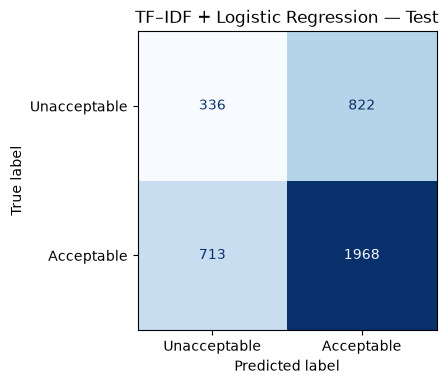

Qualitative error examples (incorrect high-confidence predictions):


,sentence,label,category,source,predicted,p_acceptable,error,confidence
3991,Mira est assistante-comptable.,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.664655,True,0.664655
6724,Elle est sensée être au fait de la loi.,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.635011,True,0.635011
7475,Les Lapons élèvent des rênes.,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.618536,True,0.618536
10972,"Dans ce cours de psychanalyse, nous aborderons...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.614264,True,0.614264
20898,Elle nous surprenait par sa créativité : soi e...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.604918,True,0.604918
13071,L’ouvrière est partie il y a une heur.,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/23...,1,0.604074,True,0.604074
3153,Le modèle d’enjoliveurs que vous cherchez est ...,0,anglicism,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.599796,True,0.599796
14633,Ne redisez jamais à personne ce que je viens d...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.597743,True,0.597743
20811,"En voyage, je veux goutter à tous les plats qu...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.596987,True,0.596987
11336,Le jour de l’An est le premier congé férié de ...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.595956,True,0.595956


Anglicism subset (test): 542
{'accuracy': 0.5092250922509225, 'macro_f1': 0.47082746065304204, 'mcc': -0.04315657649077991, 'f1_unacceptable': 0.3282828282828283, 'f1_acceptable': 0.6133720930232558}


In [9]:
# Single held-out test evaluation; do not use these results for changing C, tokenizer or class weight.
baseline_pred = baseline_model.predict(test_df['sentence'])
baseline_prob = baseline_model.predict_proba(test_df['sentence'])[:,1]
baseline_metrics = evaluate(test_df['label'],baseline_pred)
print('BASELINE — HELD-OUT TEST METRICS')
print(json.dumps(baseline_metrics,indent=2))
print(classification_report(test_df['label'],baseline_pred,labels=[0,1],target_names=['unacceptable','acceptable'],zero_division=0))
fig,ax = plt.subplots(figsize=(4.4,4))
ConfusionMatrixDisplay.from_predictions(test_df['label'],baseline_pred,labels=[0,1],
    display_labels=['Unacceptable','Acceptable'],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('TF–IDF + Logistic Regression — Test')
fig.tight_layout(); fig.savefig(OUT/'baseline_confusion_matrix.png',dpi=180,bbox_inches='tight');plt.show()

baseline_errors = test_df[['sentence','label','category','source']].copy()
baseline_errors['predicted'] = baseline_pred
baseline_errors['p_acceptable'] = baseline_prob
baseline_errors['error'] = baseline_errors['predicted'] != baseline_errors['label']
baseline_errors.to_csv(OUT/'baseline_test_predictions.csv',index=False)
print('Qualitative error examples (incorrect high-confidence predictions):')
display(baseline_errors[baseline_errors.error].assign(
    confidence=lambda x:np.maximum(x.p_acceptable,1-x.p_acceptable)
).sort_values('confidence',ascending=False).head(10))

if len(anglicisms):
    ang_idx = test_df['category'].eq('anglicism').values
    print('Anglicism subset (test):',int(ang_idx.sum()))
    if ang_idx.sum():
        print(evaluate(test_df['label'].to_numpy()[ang_idx],baseline_pred[ang_idx]))
with open(OUT/'baseline_metrics.json','w') as f:json.dump(baseline_metrics,f,indent=2)

## Part F — Primary neural model: word embedding → BiLSTM → dense logit

This **course-level PyTorch BiLSTM** is the primary neural model used in the progress report. It uses the final forward and backward LSTM hidden states to represent a sentence. Part H later implements a Character CNN + BiLSTM extension; Part I studies class weighting and model capacity. Attention pooling is a **future extension and was not implemented** in the current experiments.

Suggested Colab setting: **Runtime → Change runtime type → T4 GPU**. Training prints epoch losses and validation macro-F1; early stopping selects the best validation loss. Neither the word vocabulary nor model selection uses test sentences or test labels.


In [10]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:',torch.__version__,'Device:',DEVICE)

train_tokens = [tokenize(s) for s in train_df['sentence']]
word_counts = Counter(token for tokens in train_tokens for token in tokens)
word_to_id={'<PAD>':0, '<UNK>':1}
for token, count in word_counts.most_common():
    if count >= 2: word_to_id[token]=len(word_to_id)
sequence_lengths=np.array([len(tokens) for tokens in train_tokens])
MAX_LEN = min(100,max(12,int(np.ceil(np.percentile(sequence_lengths,95)))))
print('Vocabulary size:',len(word_to_id),'Max sequence length:',MAX_LEN)
print('Train tokens p50/p95/p99:',np.percentile(sequence_lengths,[50,95,99]))

class TextDataset(Dataset):
    def __init__(self, frame):
        self.rows=[]
        for text,label in zip(frame['sentence'],frame['label']):
            ids=[word_to_id.get(w,1) for w in tokenize(text)][:MAX_LEN]
            size=max(1,len(ids))
            ids=ids+[0]*(MAX_LEN-len(ids))
            self.rows.append((ids,size,float(label)))
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        ids,length,label=self.rows[i]
        return (torch.tensor(ids,dtype=torch.long),
                torch.tensor(length,dtype=torch.long),
                torch.tensor(label,dtype=torch.float32))

train_loader=DataLoader(TextDataset(train_df),batch_size=128,shuffle=True)
val_loader=DataLoader(TextDataset(val_df),batch_size=256,shuffle=False)
test_loader=DataLoader(TextDataset(test_df),batch_size=256,shuffle=False)

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=64, dropout=0.30):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,embedding_dim,padding_idx=0)
        self.lstm=nn.LSTM(embedding_dim,hidden_dim,num_layers=1,
                          bidirectional=True,batch_first=True)
        self.drop=nn.Dropout(dropout)
        self.fc=nn.Linear(2*hidden_dim,1)
    def forward(self,ids,lengths):
        embedded=self.embedding(ids)
        packed=pack_padded_sequence(embedded,lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,(h,_) = self.lstm(packed)
        representation=torch.cat([h[-2],h[-1]],dim=1)
        return self.fc(self.drop(representation)).squeeze(1)  # raw logits

net=BiLSTMClassifier(len(word_to_id)).to(DEVICE)
print(net)
print('Trainable parameters:',sum(p.numel() for p in net.parameters() if p.requires_grad))

PyTorch: 2.11.0+cu128 Device: cuda
Vocabulary size: 11519 Max sequence length: 20
Train tokens p50/p95/p99: [12. 20. 25.]
BiLSTMClassifier(
  (embedding): Embedding(11519, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 803905


Epoch 01 | train loss=0.4133 | val loss=0.4998 | val macro-F1=0.4901 | val MCC=-0.0198
Epoch 02 | train loss=0.4035 | val loss=0.5145 | val macro-F1=0.4902 | val MCC=-0.0193
Epoch 03 | train loss=0.3991 | val loss=0.5254 | val macro-F1=0.4861 | val MCC=-0.0268
Epoch 04 | train loss=0.3956 | val loss=0.5902 | val macro-F1=0.4856 | val MCC=-0.0282
Early stopped after 4 epochs


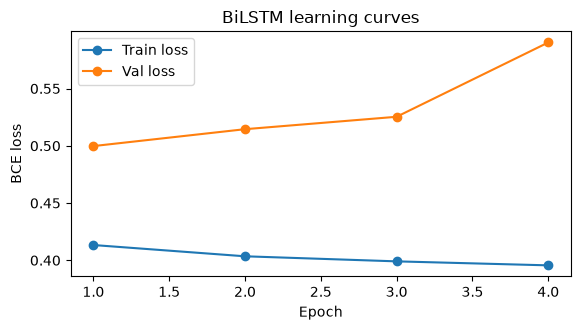

Best validation loss: 0.4998


In [11]:
def neural_epoch(model,loader,criterion,optimizer=None):
    training = optimizer is not None
    model.train(training)
    losses,total,n=0.0,0,0
    ys,ps=[],[]
    for ids,lengths,labels in loader:
        ids,lengths,labels=ids.to(DEVICE),lengths.to(DEVICE),labels.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(ids,lengths)
            loss=criterion(logits,labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        batch_n=len(labels)
        losses+=loss.item()*batch_n
        n+=batch_n
        ys.extend(labels.detach().cpu().numpy().tolist())
        ps.extend(torch.sigmoid(logits.detach()).cpu().numpy().tolist())
    return losses/n,np.array(ys,dtype=int),np.array(ps)

train_pos=int(train_df['label'].sum());train_neg=len(train_df)-train_pos
# BCEWithLogitsLoss uses pos_weight=negative/positive; positive label is 1 = acceptable.
pos_weight=torch.tensor([train_neg/max(train_pos,1)],device=DEVICE)
criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer=torch.optim.Adam(net.parameters(),lr=1e-3,weight_decay=1e-5)
history=[]
best_state=None
best_val_loss=float('inf')
patience=3
stale=0
for epoch in range(1,13):
    train_loss,_,_ = neural_epoch(net,train_loader,criterion,optimizer)
    val_loss,yval,pval = neural_epoch(net,val_loader,criterion)
    val_pred=(pval>=0.5).astype(int)
    val_m=evaluate(yval,val_pred)
    history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,**val_m})
    print(f'Epoch {epoch:02d} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | '
          f'val macro-F1={val_m["macro_f1"]:.4f} | val MCC={val_m["mcc"]:.4f}')
    if val_loss < best_val_loss - 1e-4:
        best_val_loss=val_loss
        best_state=copy.deepcopy(net.state_dict())
        stale=0
    else:
        stale+=1
        if stale>=patience:
            print('Early stopped after',epoch,'epochs')
            break

assert best_state is not None
net.load_state_dict(best_state)
history_df=pd.DataFrame(history)
history_df.to_csv(OUT/'bilstm_training_history.csv',index=False)
fig, ax=plt.subplots(figsize=(6,3.4))
ax.plot(history_df['epoch'],history_df['train_loss'],marker='o',label='Train loss')
ax.plot(history_df['epoch'],history_df['val_loss'],marker='o',label='Val loss')
ax.set(xlabel='Epoch',ylabel='BCE loss',title='BiLSTM learning curves')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'bilstm_learning_curves.png',dpi=180,bbox_inches='tight')
plt.show()
print('Best validation loss:',round(best_val_loss,4))

PRIMARY BILSTM — HELD-OUT TEST METRICS
{
  "accuracy": 0.5543110184943996,
  "macro_f1": 0.46723875490227806,
  "mcc": -0.06546048825782402,
  "f1_unacceptable": 0.25185832968954963,
  "f1_acceptable": 0.6826191801150064
}
              precision    recall  f1-score   support

unacceptable       0.26      0.25      0.25      1158
  acceptable       0.68      0.69      0.68      2681

    accuracy                           0.55      3839
   macro avg       0.47      0.47      0.47      3839
weighted avg       0.55      0.55      0.55      3839



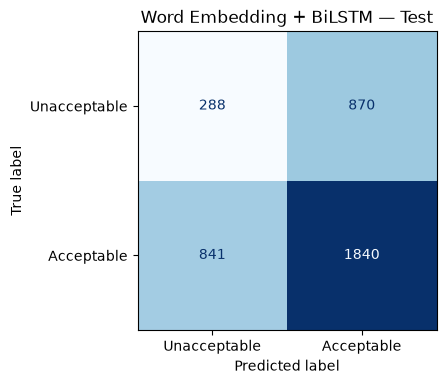

Qualitative error examples:


,sentence,label,category,source,predicted,p_acceptable,error,confidence
17744,"Respectivements nées à Sorel et à Laval, Carol...",0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/25...,1,0.939671,True,0.939671
9395,L’artisane a garni la couverture d’un galon po...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.935296,True,0.935296
10646,Découper des images et les coloriés permet aux...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.929151,True,0.929151
5227,Découper des images et les colorié permet aux ...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.929151,True,0.929151
4846,Découper des images et les coloriées permet au...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.929151,True,0.929151
1100,Découper des images et les coloriée permet aux...,0,semantic,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.929151,True,0.929151
4473,Élizabeth projette entreprendre des études uni...,0,syntax,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.927493,True,0.927493
13083,Il neigeait; Fiona lisais confortablement dans...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.926898,True,0.926898
4338,Il neigeais; Fiona lisais confortablement dans...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/24...,1,0.926898,True,0.926898
12701,Ce laisser-aller constant annonçait les prémis...,0,morphology,https://vitrinelinguistique.oqlf.gouv.qc.ca/22...,1,0.925083,True,0.925083


Anglicism examples in test: 542
BiLSTM anglicism subset: {'accuracy': 0.45940959409594095, 'macro_f1': 0.4139199816949177, 'mcc': -0.15697807250869286, 'f1_unacceptable': 0.2506393861892583, 'f1_acceptable': 0.5772005772005772}
TEST RESULTS — for report table (no invented numbers):


,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
TF-IDF + LogReg,0.6002,0.5120,0.0249,0.3045,0.7194
Word Embedding + BiLSTM,0.5543,0.4672,-0.0655,0.2519,0.6826


In [12]:
# Single final held-out test evaluation (do not retune after reading it).
_, ytest_bilstm, ptest_bilstm = neural_epoch(net,test_loader,criterion)
bilstm_pred=(ptest_bilstm>=0.5).astype(int)
primary_metrics=evaluate(ytest_bilstm,bilstm_pred)
print('PRIMARY BILSTM — HELD-OUT TEST METRICS')
print(json.dumps(primary_metrics,indent=2))
print(classification_report(ytest_bilstm,bilstm_pred,labels=[0,1],target_names=['unacceptable','acceptable'],zero_division=0))
fig,ax=plt.subplots(figsize=(4.4,4))
ConfusionMatrixDisplay.from_predictions(ytest_bilstm,bilstm_pred,labels=[0,1],
    display_labels=['Unacceptable','Acceptable'],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Word Embedding + BiLSTM — Test')
fig.tight_layout();fig.savefig(OUT/'bilstm_confusion_matrix.png',dpi=180,bbox_inches='tight');plt.show()

bilstm_errors=test_df[['sentence','label','category','source']].copy()
bilstm_errors['predicted']=bilstm_pred
bilstm_errors['p_acceptable']=ptest_bilstm
bilstm_errors['error']=(bilstm_errors['predicted'] != bilstm_errors['label'])
bilstm_errors.to_csv(OUT/'bilstm_test_predictions.csv',index=False)
print('Qualitative error examples:')
display(bilstm_errors[bilstm_errors.error].assign(
    confidence=lambda x:np.maximum(x.p_acceptable,1-x.p_acceptable)
).sort_values('confidence',ascending=False).head(10))
ang_idx = test_df['category'].eq('anglicism').values
print('Anglicism examples in test:',int(ang_idx.sum()))
if ang_idx.sum():
    print('BiLSTM anglicism subset:',evaluate(ytest_bilstm[ang_idx],bilstm_pred[ang_idx]))

comparison=pd.DataFrame({'TF-IDF + LogReg':baseline_metrics,'Word Embedding + BiLSTM':primary_metrics}).T
print('TEST RESULTS — for report table (no invented numbers):')
display(comparison.round(4))
comparison.to_csv(OUT/'model_comparison.csv')
with open(OUT/'bilstm_metrics.json','w') as f:json.dump(primary_metrics,f,indent=2)
# Save model + vocabulary for reproducibility.
torch.save({'model_state':net.state_dict(),'vocabulary':word_to_id,
            'max_len':MAX_LEN,'embedding_dim':64,'hidden_dim':64,'seed':SEED}, OUT/'bilstm.pt')

In [14]:
# Part F.1 - Validation diagnostics
# Do NOT tune using the test set.

def token_diagnostics(frame):
    sequences = [tokenize(s) for s in frame["sentence"]]
    total_tokens = sum(len(s) for s in sequences)
    oov_tokens = sum(
        token not in word_to_id
        for seq in sequences for token in seq
    )
    truncated = sum(len(seq) > MAX_LEN for seq in sequences)

    return {
        "OOV rate": oov_tokens / max(total_tokens, 1),
        "Truncated sentence rate": truncated / len(sequences),
        "Average length": total_tokens / len(sequences)
    }

print("TOKEN DIAGNOSTICS")
display(pd.DataFrame({
    "train": token_diagnostics(train_df),
    "validation": token_diagnostics(val_df),
    "test": token_diagnostics(test_df)
}).T.round(4))

# Evaluate the saved best BiLSTM checkpoint on validation
val_loss, y_val, val_probs = neural_epoch(
    net, val_loader, criterion
)

print("\nVALIDATION CONFUSION MATRIX (threshold=0.5)")
print(confusion_matrix(y_val, (val_probs >= 0.5).astype(int)))

# Threshold exploration: validation ONLY
results = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (val_probs >= threshold).astype(int)
    metrics = evaluate(y_val, pred)
    results.append({
        "threshold": round(float(threshold), 2),
        "macro_f1": metrics["macro_f1"],
        "mcc": metrics["mcc"],
        "accuracy": metrics["accuracy"],
        "f1_unacceptable": metrics["f1_unacceptable"]
    })

threshold_results = pd.DataFrame(results)
print("\nVALIDATION THRESHOLD ANALYSIS")
display(
    threshold_results.sort_values(
        "macro_f1", ascending=False
    ).round(4)
)

TOKEN DIAGNOSTICS


,OOV rate,Truncated sentence rate,Average length
train,0.0355,0.0366,12.1313
validation,0.1000,0.0372,11.8535
test,0.1018,0.0375,11.8760



VALIDATION CONFUSION MATRIX (threshold=0.5)
[[ 339  819]
 [ 805 1771]]

VALIDATION THRESHOLD ANALYSIS


,threshold,macro_f1,mcc,accuracy,f1_unacceptable
6,0.50,0.4901,-0.0198,0.5651,0.2945
7,0.55,0.4868,-0.0215,0.5372,0.3261
5,0.45,0.4836,-0.0167,0.6085,0.2297
8,0.60,0.4777,-0.0175,0.5024,0.3641
9,0.65,0.4626,-0.0003,0.4689,0.4043
10,0.70,0.4353,-0.0112,0.4360,0.4160
4,0.40,0.4272,-0.0058,0.6786,0.0476
11,0.75,0.4124,-0.0152,0.4127,0.4261
0,0.20,0.4082,0.0000,0.6899,0.0000
1,0.25,0.4082,0.0000,0.6899,0.0000


In [15]:
# Part F.2 — Label and loss sanity check

print("TRAIN LABEL COUNTS")
print(train_df["label"].value_counts())

print("\nVALIDATION LABEL COUNTS")
print(val_df["label"].value_counts())

print("\nMODEL OUTPUT LAYER")
print(net.fc)

print("\nPOSITIVE CLASS WEIGHT")
n_positive = (train_df["label"] == 1).sum()
n_negative = (train_df["label"] == 0).sum()
print("Expected positive weight:", n_negative / n_positive)

print("\nPREDICTION PROBABILITY DISTRIBUTION")
print(pd.Series(val_probs).describe())

print("\nMEAN PROBABILITY BY TRUE LABEL")
print(
    pd.DataFrame({
        "label": y_val,
        "probability": val_probs
    }).groupby("label")["probability"].agg(
        ["mean", "median", "std"]
    )
)

TRAIN LABEL COUNTS
label
1    12222
0     5358
Name: count, dtype: int64

VALIDATION LABEL COUNTS
label
1    2576
0    1158
Name: count, dtype: int64

MODEL OUTPUT LAYER
Linear(in_features=128, out_features=1, bias=True)

POSITIVE CLASS WEIGHT
Expected positive weight: 0.4383897889052528

PREDICTION PROBABILITY DISTRIBUTION
count    3734.000000
mean        0.627142
std         0.162324
min         0.345527
25%         0.469516
50%         0.612216
75%         0.775871
max         0.950434
dtype: float64

MEAN PROBABILITY BY TRUE LABEL
           mean    median       std
label                              
0      0.630462  0.615656  0.160692
1      0.625649  0.609991  0.163062


## Part G — Why add a Character CNN?

**Motivation.** On the source-disjoint validation set, some tokens are outside the training word vocabulary. A character-level CNN may recover useful spelling and morphology cues even when a whole word is represented as `<UNK>`. The following experiments test this hypothesis; improvement is **not assumed**.


**Proposed E3 architecture:**

```text
French sentence
  ├─ Word token IDs → Word Embedding (64 dimensions) ─┐
  └─ Character IDs → Char Embedding → CNN (32 filters) ─┤
                                                         ↓
                                                Concatenate features
                                                         ↓
                                                   BiLSTM (64 × 2)
                                                         ↓
                                                   Dense → logit
                                                         ↓
                                           Acceptable / Unacceptable
```

Part H implements this network; Part I compares loss weighting and model size. An attention-based model is an optional **future** direction, not a result presented here.


| Experiment | Model / configuration | Purpose | Status |
|---|---|---|---|
| E1 | TF–IDF + Logistic Regression | Traditional non-neural baseline | Completed |
| E2 | Word Embedding + BiLSTM | Initial neural model | Completed |
| E3 | Word + Character CNN + BiLSTM | Test the contribution of character-level features | Completed (validation) |
| E4a | Word BiLSTM with unweighted BCE | Study class weighting and majority-class collapse | Completed (validation) |
| E4b | Smaller, weighted Word BiLSTM | Study model capacity | Completed (validation) |
| Future | E3 + Attention Pooling / pretrained French representations | Potential final-report extensions | Not yet implemented |


## Part H — E3: Character CNN + BiLSTM

Build the character vocabulary from training sentences only, encode each token as characters, add a CNN branch, and evaluate the resulting model **on validation data**. This section includes the trained model's saved learning curves and best validation-loss checkpoint.


In [16]:
# Part H1 — Build character vocabulary
# Character vocabulary must be built on training data only.

CHAR_MAX_LEN = 24

train_tokens = [
    tokenize(sentence)
    for sentence in train_df["sentence"]
]

char_counts = Counter(
    char
    for tokens in train_tokens
    for token in tokens
    for char in token
)

char_to_id = {"<PAD>": 0, "<UNK>": 1}

for char, count in sorted(char_counts.items()):
    char_to_id[char] = len(char_to_id)

print("Character vocabulary size:", len(char_to_id))
print("Maximum characters per word:", CHAR_MAX_LEN)

# Test with French words
examples = ["l’école", "québécois", "assurance-emploi"]

for word in examples:
    ids = [
        char_to_id.get(char, 1)
        for char in word[:CHAR_MAX_LEN]
    ]
    print(word, "->", ids)

Character vocabulary size: 85
Maximum characters per word: 24
l’école -> [44, 81, 67, 35, 47, 44, 37]
québécois -> [49, 53, 67, 34, 67, 35, 47, 41, 51]
assurance-emploi -> [33, 51, 51, 53, 50, 33, 46, 35, 37, 12, 37, 45, 48, 44, 47, 41]


In [17]:
# Part H2 — Word + Character Dataset

class WordCharDataset(Dataset):
    def __init__(self, frame):
        self.rows = []

        for text, label in zip(
            frame["sentence"], frame["label"]
        ):
            tokens = tokenize(text)[:MAX_LEN]
            length = max(1, len(tokens))

            word_ids = [
                word_to_id.get(token, 1)
                for token in tokens
            ]

            char_ids = []
            for token in tokens:
                chars = [
                    char_to_id.get(c, 1)
                    for c in token[:CHAR_MAX_LEN]
                ]

                chars += [0] * (CHAR_MAX_LEN - len(chars))
                char_ids.append(chars)

            # Padding for missing words
            padding_words = MAX_LEN - len(tokens)

            word_ids += [0] * padding_words
            char_ids += [
                [0] * CHAR_MAX_LEN
                for _ in range(padding_words)
            ]

            self.rows.append((
                word_ids,
                char_ids,
                length,
                float(label)
            ))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        word_ids, char_ids, length, label = self.rows[idx]

        return (
            torch.tensor(word_ids, dtype=torch.long),
            torch.tensor(char_ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(label, dtype=torch.float32)
        )


train_char_loader = DataLoader(
    WordCharDataset(train_df),
    batch_size=128,
    shuffle=True
)

val_char_loader = DataLoader(
    WordCharDataset(val_df),
    batch_size=256,
    shuffle=False
)

# Inspect the first batch
word_ids, char_ids, lengths, labels = next(
    iter(train_char_loader)
)

print("Word input:", word_ids.shape)
print("Character input:", char_ids.shape)
print("Lengths:", lengths.shape)
print("Labels:", labels.shape)

Word input: torch.Size([128, 20])
Character input: torch.Size([128, 20, 24])
Lengths: torch.Size([128])
Labels: torch.Size([128])


In [18]:
# Part H3 — Word + Character CNN + BiLSTM
# E3: Adds character-level features to the original BiLSTM.

class CharCNNBiLSTM(nn.Module):
    def __init__(
        self,
        word_vocab_size,
        char_vocab_size,
        word_dim=64,
        char_dim=16,
        char_filters=32,
        hidden_dim=64,
        dropout=0.30
    ):
        super().__init__()

        # 1. Word-level features
        self.word_embedding = nn.Embedding(
            word_vocab_size, word_dim, padding_idx=0
        )

        # 2. Character-level features
        self.char_embedding = nn.Embedding(
            char_vocab_size, char_dim, padding_idx=0
        )

        self.char_conv = nn.Conv1d(
            in_channels=char_dim,
            out_channels=char_filters,
            kernel_size=3,
            padding=1
        )

        # 3. Contextual sentence representation
        self.lstm = nn.LSTM(
            input_size=word_dim + char_filters,
            hidden_size=hidden_dim,
            num_layers=1,
            bidirectional=True,
            batch_first=True
        )

        # 4. Classification
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, word_ids, char_ids, lengths):
        B, T, C = char_ids.shape

        # Word embeddings: [B, T, 64]
        word_features = self.word_embedding(word_ids)

        # Flatten words: [B*T, C]
        chars = char_ids.reshape(B * T, C)

        # Character embeddings: [B*T, C, 16]
        char_emb = self.char_embedding(chars)

        # Conv1d expects [batch, channels, length]
        char_emb = char_emb.transpose(1, 2)

        # Character CNN: [B*T, 32, C]
        conv_out = torch.relu(self.char_conv(char_emb))

        # Ignore padded character positions during pooling
        valid_chars = chars.ne(0).unsqueeze(1)
        conv_out = conv_out.masked_fill(
            ~valid_chars, torch.finfo(conv_out.dtype).min
        )

        # Max pooling over character positions
        char_features = conv_out.max(dim=2).values

        # Entirely padded words should have zero features
        empty_words = ~chars.ne(0).any(dim=1)
        char_features = char_features.masked_fill(
            empty_words.unsqueeze(1), 0.0
        )

        # Restore: [B, T, 32]
        char_features = char_features.reshape(B, T, -1)

        # Concatenate word + character features
        # [B, T, 96]
        combined = torch.cat(
            [word_features, char_features], dim=2
        )

        # Pack actual sentence lengths
        packed = pack_padded_sequence(
            combined,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (h, _) = self.lstm(packed)

        # Forward + backward final states: [B, 128]
        representation = torch.cat(
            [h[-2], h[-1]], dim=1
        )

        # Return raw logits for BCEWithLogitsLoss
        return self.fc(
            self.dropout(representation)
        ).squeeze(1)


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

char_net = CharCNNBiLSTM(
    word_vocab_size=len(word_to_id),
    char_vocab_size=len(char_to_id)
).to(DEVICE)

print(char_net)

print(
    "Trainable parameters:",
    sum(p.numel() for p in char_net.parameters()
        if p.requires_grad)
)

# Forward-pass sanity check
char_net.eval()
with torch.no_grad():
    logits = char_net(
        word_ids.to(DEVICE),
        char_ids.to(DEVICE),
        lengths.to(DEVICE)
    )

print("Logits shape:", logits.shape)
assert logits.shape == (128,)
assert torch.isfinite(logits).all()

print("Forward pass successful!")

CharCNNBiLSTM(
  (word_embedding): Embedding(11519, 64, padding_idx=0)
  (char_embedding): Embedding(85, 16, padding_idx=0)
  (char_conv): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (lstm): LSTM(96, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 823217
Logits shape: torch.Size([128])
Forward pass successful!


Epoch 01 | Train loss=0.4161 | Val loss=0.5059 | Macro-F1=0.4889 | MCC=-0.0217
Epoch 02 | Train loss=0.4050 | Val loss=0.5198 | Macro-F1=0.4890 | MCC=-0.0219
Epoch 03 | Train loss=0.3997 | Val loss=0.5093 | Macro-F1=0.4871 | MCC=-0.0254
Epoch 04 | Train loss=0.3956 | Val loss=0.6150 | Macro-F1=0.4887 | MCC=-0.0173
Early stopped at epoch 4


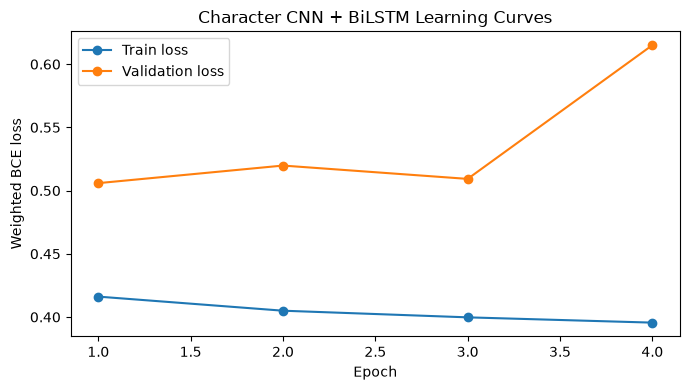


Best epoch: 1
Best validation loss: 0.5058962676572365
Restored checkpoint validation metrics:
{
  "accuracy": 0.5546331012319229,
  "macro_f1": 0.48891141320026155,
  "mcc": -0.021677927716176146,
  "f1_unacceptable": 0.3056367432150313,
  "f1_acceptable": 0.6721860831854918
}


In [19]:
# Part H4 — Train Character CNN + BiLSTM
# Train/validation only. Do not evaluate test data yet.

def char_neural_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_probs = []

    for words, chars, lengths, labels in loader:
        words = words.to(DEVICE)
        chars = chars.to(DEVICE)
        lengths = lengths.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.set_grad_enabled(training):
            logits = model(words, chars, lengths)
            loss = criterion(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )
                optimizer.step()

        batch_size = len(labels)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(
            labels.detach().cpu().numpy().tolist()
        )
        all_probs.extend(
            torch.sigmoid(logits.detach()).cpu().numpy().tolist()
        )

    return (
        total_loss / total_samples,
        np.array(all_labels, dtype=int),
        np.array(all_probs)
    )


# Use the same loss configuration as E2
train_pos = int(train_df["label"].sum())
train_neg = len(train_df) - train_pos

char_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [train_neg / train_pos],
        device=DEVICE
    )
)

char_optimizer = torch.optim.Adam(
    char_net.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

char_history = []
best_char_state = None
best_char_val_loss = float("inf")
best_char_epoch = None
patience = 3
stale = 0

for epoch in range(1, 13):

    train_loss, _, _ = char_neural_epoch(
        char_net,
        train_char_loader,
        char_criterion,
        char_optimizer
    )

    val_loss, y_val_char, p_val_char = char_neural_epoch(
        char_net,
        val_char_loader,
        char_criterion
    )

    val_pred = (p_val_char >= 0.5).astype(int)
    metrics = evaluate(y_val_char, val_pred)

    char_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        **metrics
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss={train_loss:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Macro-F1={metrics['macro_f1']:.4f} | "
        f"MCC={metrics['mcc']:.4f}"
    )

    if val_loss < best_char_val_loss - 1e-4:
        best_char_val_loss = val_loss
        best_char_epoch = epoch
        best_char_state = copy.deepcopy(
            char_net.state_dict()
        )
        stale = 0
    else:
        stale += 1
        if stale >= patience:
            print("Early stopped at epoch", epoch)
            break

# Restore best validation-loss checkpoint
char_net.load_state_dict(best_char_state)

char_history_df = pd.DataFrame(char_history)
char_history_df.to_csv(
    OUT / "charcnn_bilstm_training_history.csv",
    index=False
)

# Learning curves
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    char_history_df["epoch"],
    char_history_df["train_loss"],
    marker="o",
    label="Train loss"
)

ax.plot(
    char_history_df["epoch"],
    char_history_df["val_loss"],
    marker="o",
    label="Validation loss"
)

ax.set(
    xlabel="Epoch",
    ylabel="Weighted BCE loss",
    title="Character CNN + BiLSTM Learning Curves"
)
ax.legend()
plt.tight_layout()

plt.savefig(
    OUT / "charcnn_bilstm_learning_curves.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Final validation evaluation with saved checkpoint
val_loss, y_val_char, p_val_char = char_neural_epoch(
    char_net, val_char_loader, char_criterion
)
val_metrics = evaluate(
    y_val_char,
    (p_val_char >= 0.5).astype(int)
)

print("\nBest epoch:", best_char_epoch)
print("Best validation loss:", best_char_val_loss)
print("Restored checkpoint validation metrics:")
print(json.dumps(val_metrics, indent=2))

# Save checkpoint
torch.save(
    {
        "model_state_dict": best_char_state,
        "word_to_id": word_to_id,
        "char_to_id": char_to_id,
        "max_len": MAX_LEN,
        "char_max_len": CHAR_MAX_LEN,
        "best_epoch": best_char_epoch
    },
    OUT / "charcnn_bilstm_best.pt"
)

## Part I — E4: Class-weight and model-capacity ablations

I1–I3 explore unweighted BCE. I4 repeats the weighted and unweighted word-BiLSTM configurations with the **same** optimizer weight decay and data-order seed, and adds a smaller weighted model. The controlled experiment table uses **validation** results; it is not a new test-set evaluation.


In [20]:
# Part I1 — Unweighted BCE experiment
# Compare with E2 using the same training protocol.

import inspect

print("Original model class:", type(net).__name__)
print("Original model signature:")
print(inspect.signature(type(net)))

print("\nOriginal model architecture:")
print(net)

print("\nOriginal optimizer/loss configuration:")
print("New experiment: BCEWithLogitsLoss, pos_weight=None")

Original model class: BiLSTMClassifier
Original model signature:
(vocab_size, embedding_dim=64, hidden_dim=64, dropout=0.3)

Original model architecture:
BiLSTMClassifier(
  (embedding): Embedding(11519, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Original optimizer/loss configuration:
New experiment: BCEWithLogitsLoss, pos_weight=None


In [21]:
# Part I2 — Unweighted BiLSTM experiment

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Initialize a fresh model
unweighted_net = BiLSTMClassifier(
    vocab_size=len(word_to_id),
    embedding_dim=64,
    hidden_dim=64,
    dropout=0.3
).to(DEVICE)

# Only intentional change: no positive-class weighting
unweighted_criterion = nn.BCEWithLogitsLoss()

unweighted_optimizer = torch.optim.Adam(
    unweighted_net.parameters(),
    lr=1e-3
)

history_unweighted = []
best_unweighted_state = None
best_unweighted_val_loss = float("inf")
best_unweighted_epoch = None
stale = 0
patience = 3

for epoch in range(1, 13):

    train_loss, _, _ = neural_epoch(
        unweighted_net,
        train_loader,
        unweighted_criterion,
        unweighted_optimizer
    )

    val_loss, y_val_unweighted, p_val_unweighted = neural_epoch(
        unweighted_net,
        val_loader,
        unweighted_criterion
    )

    val_pred = (p_val_unweighted >= 0.5).astype(int)
    metrics = evaluate(y_val_unweighted, val_pred)

    history_unweighted.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        **metrics
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss={train_loss:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Macro-F1={metrics['macro_f1']:.4f} | "
        f"MCC={metrics['mcc']:.4f}"
    )

    if val_loss < best_unweighted_val_loss - 1e-4:
        best_unweighted_val_loss = val_loss
        best_unweighted_epoch = epoch
        best_unweighted_state = copy.deepcopy(
            unweighted_net.state_dict()
        )
        stale = 0
    else:
        stale += 1
        if stale >= patience:
            print("Early stopped at epoch", epoch)
            break

# Restore best model
unweighted_net.load_state_dict(best_unweighted_state)

unweighted_history_df = pd.DataFrame(history_unweighted)

print("\nBest epoch:", best_unweighted_epoch)
print("Best validation loss:", best_unweighted_val_loss)

# Save history and model
unweighted_history_df.to_csv(
    OUT / "unweighted_bilstm_history.csv",
    index=False
)

torch.save(
    unweighted_net.state_dict(),
    OUT / "unweighted_bilstm_best.pt"
)

Epoch 01 | Train loss=0.6078 | Val loss=0.7719 | Macro-F1=0.4082 | MCC=0.0000
Epoch 02 | Train loss=0.5907 | Val loss=0.7360 | Macro-F1=0.4081 | MCC=-0.0110
Epoch 03 | Train loss=0.5820 | Val loss=0.7367 | Macro-F1=0.4096 | MCC=-0.0023
Epoch 04 | Train loss=0.5732 | Val loss=0.8135 | Macro-F1=0.4104 | MCC=0.0025
Epoch 05 | Train loss=0.5604 | Val loss=0.8045 | Macro-F1=0.4120 | MCC=0.0062
Early stopped at epoch 5

Best epoch: 2
Best validation loss: 0.735973936609872


UNWEIGHTED BiLSTM — VALIDATION
{
  "accuracy": 0.689608998393144,
  "macro_f1": 0.40814709145664924,
  "mcc": -0.010973681608740474,
  "f1_unacceptable": 0.0,
  "f1_acceptable": 0.8162941829132985
}

Confusion matrix:
[[   0 1158]
 [   1 2575]]

Probability means by true label:


label
0    0.799674
1    0.794647
Name: probability, dtype: float64

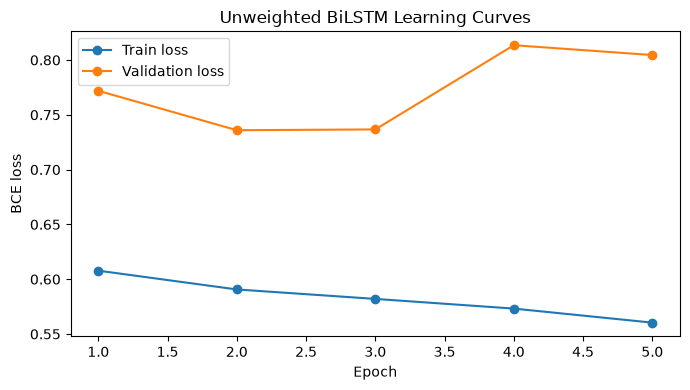

In [22]:
# Part I3 — Validation evaluation and comparison

unweighted_net.eval()

val_loss, y_val_unweighted, p_val_unweighted = neural_epoch(
    unweighted_net,
    val_loader,
    unweighted_criterion
)

unweighted_pred = (
    p_val_unweighted >= 0.5
).astype(int)

unweighted_metrics = evaluate(
    y_val_unweighted,
    unweighted_pred
)

print("UNWEIGHTED BiLSTM — VALIDATION")
print(json.dumps(unweighted_metrics, indent=2))

print("\nConfusion matrix:")
print(confusion_matrix(y_val_unweighted, unweighted_pred))

print("\nProbability means by true label:")
display(
    pd.DataFrame({
        "label": y_val_unweighted,
        "probability": p_val_unweighted
    }).groupby("label")["probability"].mean()
)

# Learning curves
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    unweighted_history_df["epoch"],
    unweighted_history_df["train_loss"],
    marker="o",
    label="Train loss"
)
ax.plot(
    unweighted_history_df["epoch"],
    unweighted_history_df["val_loss"],
    marker="o",
    label="Validation loss"
)
ax.set(
    xlabel="Epoch",
    ylabel="BCE loss",
    title="Unweighted BiLSTM Learning Curves"
)
ax.legend()
plt.tight_layout()
plt.savefig(
    OUT / "unweighted_bilstm_learning_curves.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

In [23]:
# Part I4 — Controlled BiLSTM experiments
# All experiments use identical training settings.

def run_controlled_experiment(
    name, embedding_dim, hidden_dim, weighted,
    seed=360
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Same randomized batch order for every experiment
    generator = torch.Generator().manual_seed(seed)

    controlled_loader = DataLoader(
        TextDataset(train_df),
        batch_size=128,
        shuffle=True,
        generator=generator
    )

    model = BiLSTMClassifier(
        vocab_size=len(word_to_id),
        embedding_dim=embedding_dim,
        hidden_dim=hidden_dim,
        dropout=0.3
    ).to(DEVICE)

    if weighted:
        pos_weight = torch.tensor(
            [train_neg / train_pos],
            device=DEVICE
        )
        loss_fn = nn.BCEWithLogitsLoss(
            pos_weight=pos_weight
        )
    else:
        loss_fn = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-5
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = None
    stale = 0
    history = []

    for epoch in range(1, 13):
        tr_loss, _, _ = neural_epoch(
            model, controlled_loader, loss_fn, optimizer
        )

        va_loss, y, p = neural_epoch(
            model, val_loader, loss_fn
        )

        metrics = evaluate(y, (p >= 0.5).astype(int))

        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "val_loss": va_loss,
            **metrics
        })

        if va_loss < best_loss - 1e-4:
            best_loss = va_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= 3:
                break

    model.load_state_dict(best_state)

    _, y, p = neural_epoch(model, val_loader, loss_fn)
    pred = (p >= 0.5).astype(int)
    metrics = evaluate(y, pred)

    result = {
        "model": name,
        "parameters": sum(
            x.numel() for x in model.parameters()
        ),
        "best_epoch": best_epoch,
        "val_loss": best_loss,
        "predicted_unacceptable": int((pred == 0).sum()),
        **metrics
    }

    pd.DataFrame(history).to_csv(
        OUT / f"{name}_history.csv", index=False
    )

    torch.save(
        model.state_dict(),
        OUT / f"{name}_best.pt"
    )

    print(
        f"{name}: Macro-F1={metrics['macro_f1']:.4f}, "
        f"MCC={metrics['mcc']:.4f}, "
        f"best epoch={best_epoch}"
    )

    return result


experiments = [
    ("E2_weighted_64", 64, 64, True),
    ("E4a_unweighted_64", 64, 64, False),
    ("E4b_weighted_32", 32, 32, True)
]

controlled_results = []

for name, emb, hidden, weighted in experiments:
    result = run_controlled_experiment(
        name, emb, hidden, weighted
    )
    controlled_results.append(result)

comparison_df = pd.DataFrame(controlled_results)

print("\nCONTROLLED VALIDATION COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    OUT / "controlled_validation_comparison.csv",
    index=False
)

E2_weighted_64: Macro-F1=0.4852, MCC=-0.0292, best epoch=2
E4a_unweighted_64: Macro-F1=0.4081, MCC=-0.0110, best epoch=4
E4b_weighted_32: Macro-F1=0.4848, MCC=-0.0304, best epoch=1

CONTROLLED VALIDATION COMPARISON


,model,parameters,best_epoch,val_loss,predicted_unacceptable,accuracy,macro_f1,mcc,f1_unacceptable,f1_acceptable
0,E2_weighted_64,803905,2,0.5176,1221,0.5530,0.4852,-0.0292,0.2984,0.6720
1,E4a_unweighted_64,803905,4,0.7062,1,0.6896,0.4081,-0.0110,0.0000,0.8163
2,E4b_weighted_32,385569,1,0.4787,1119,0.5632,0.4848,-0.0304,0.2837,0.6858


## Final Part — Export evidence and plan independent final testing

The earlier cells write files into `qfrcola_results/`. Examples include:

- **Data processing:** `train.csv`, `validation.csv`, `test.csv`, `split_summary.csv`, `label_counts.csv`, `category_counts.csv`, `split_distributions.png`.
- **E1 baseline:** `baseline_metrics.json`, `baseline_confusion_matrix.png`, `baseline_test_predictions.csv`.
- **E2 word BiLSTM:** `bilstm_metrics.json`, `bilstm_confusion_matrix.png`, `bilstm_learning_curves.png`, `bilstm_test_predictions.csv`, training history/checkpoint.
- **E3 Character CNN + BiLSTM:** `charcnn_bilstm_training_history.csv`, `charcnn_bilstm_learning_curves.png`, `charcnn_bilstm_best.pt` (validation metrics printed in Part H).
- **E4 training ablations:** `unweighted_bilstm_history.csv`, `unweighted_bilstm_best.pt`, `unweighted_bilstm_learning_curves.png`, `controlled_validation_comparison.csv`, and three model checkpoints/history files.

**Quantitative evidence:** saved notebook outputs include validation learning curves and comparison tables, plus held-out test predictions for the initial TF–IDF and word-level BiLSTM models. Do not treat validation-only E3/E4 results as held-out test results.

**Qualitative evidence:** review real false positives and false negatives, particularly anglicism examples, including the sentence, label, prediction, and relevant linguistic pattern.

**New-data plan (not yet completed):** obtain an independent set of manually checked examples from OQLF source pages whose URLs are absent from all current splits. Keep source URLs, access dates, and label rationale; do not use this future set to tune a model.

**Limits:** linguistic acceptability here reflects the corpus's particular normative criteria, not an objective ranking of Quebec French. Source-disjoint splitting may shift category distributions. The models classify individual sentences and do not generate corrections.

**Reproducing the analysis:** run notebook cells top-to-bottom and compare the newly generated outputs with the saved outputs. Runtime/library differences can affect exact metrics.


In [25]:
# Optional: archive generated plots and CSVs to upload into this chat.
import zipfile
with zipfile.ZipFile('qfrcola_results.zip','w',zipfile.ZIP_DEFLATED) as z:
    for file in OUT.rglob('*'):
        if file.is_file(): z.write(file,arcname=str(file))
print('Created qfrcola_results.zip')
print('In Colab: open the Files pane and download qfrcola_results.zip to share results.')

Created qfrcola_results.zip
In Colab: open the Files pane and download qfrcola_results.zip to share results.
